# Anomaly Detection for Vibration-Based Fault Diagnosis
## Using One-Class SVM and Isolation Forest

This notebook walks through an end-to-end anomaly detection pipeline applied to **mechanical bearing fault diagnosis**. We simulate vibration sensor data, extract physics-inspired features, and train two unsupervised detectors — **One-Class SVM** and **Isolation Forest** — comparing their decision boundaries and sensitivity to key hyperparameters.

### What you'll learn
- How to generate realistic synthetic vibration data (inner-race bearing fault)
- How to extract time-domain and frequency-domain diagnostic features
- How **One-Class SVM** works and how `ν` controls the decision boundary
- How **Isolation Forest** works and how `n_estimators` affects stability
- How to evaluate anomaly detectors with precision, recall, F1, and PCA visualizations

### Prerequisite knowledge
Basic Python, NumPy, and familiarity with scikit-learn. No prior knowledge of anomaly detection required.

---
*Algorithms covered: OC-SVM · Isolation Forest · PCA (for visualization)*

In [15]:
# Import & Configurations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap
import seaborn as sns
from scipy import stats, signal

from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_curve, auc,
    precision_recall_curve, average_precision_score, f1_score,
    precision_score, recall_score, accuracy_score, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings('ignore')

# Aesthetics
plt.rcParams.update({
    'figure.figsize': (12, 5),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'font.size': 11,
    'legend.fontsize': 10,
    'figure.dpi': 150,
})
sns.set_style("whitegrid")

SEED = 42
np.random.seed(42)
print("All libraries loaded successfully.")


All libraries loaded successfully.


## §1 — Synthetic Vibration Data

We simulate a rotating machine (shaft at 30 Hz) fitted with an accelerometer at 10 kHz. 
Two classes of windows are generated:

- **Normal**: shaft harmonics + broadband noise
- **Fault**: same as normal, plus periodic **impulse bursts** at the Ball Pass Frequency (Inner race) ≈ 156 Hz — each burst decays exponentially and excites a structural resonance at 3,500 Hz

Real-world bearing datasets (e.g. CWRU, PRONOSTIA) follow the same physical model.

In [16]:
# ============================================================
# §1 — Generate Synthetic Vibration Data
# ============================================================

fs = 10000          # Sampling frequency (Hz) - Increased to 10kHz to capture high-freq resonance
T_window = 0.5     # Window length in seconds
N_samples = int(fs * T_window)  # 5,000 samples per window
n_windows = 500    # Total number of measurement windows
fault_ratio = 0.10 # ~10% faulty windows
shaft_freq = 30    # Shaft rotation frequency (Hz) — 1800 RPM
bpfi = 5.2 * shaft_freq  # Ball Pass Frequency Inner race ≈ 156 Hz

t = np.arange(N_samples) / fs  # Time vector for one window

def generate_normal_vibration(t, shaft_freq, fs):
    """Normal bearing vibration: shaft harmonics + broadband noise."""
    sig = (1.0 * np.sin(2 * np.pi * shaft_freq * t) +
           0.5 * np.sin(2 * np.pi * 2 * shaft_freq * t + 0.3) +
           0.3 * np.sin(2 * np.pi * 3 * shaft_freq * t + 1.1) +
           0.15 * np.sin(2 * np.pi * 4 * shaft_freq * t + 0.7))
    noise = 0.4 * np.random.randn(len(t))
    return sig + noise

def generate_faulty_vibration(t, shaft_freq, bpfi, fs):
    """Inner-race fault: normal vibration + periodic impulses at BPFI."""
    normal = generate_normal_vibration(t, shaft_freq, fs)
    
    # Periodic impulses at BPFI — short exponentially-decaying bursts
    impulse_period = 1.0 / bpfi
    impulse_times = np.arange(0, t[-1], impulse_period)
    impulses = np.zeros_like(t)
    for ti in impulse_times:
        idx = np.argmin(np.abs(t - ti))
        if idx < len(t) - 10:
            # Exponentially-decaying impact burst (ring-down)
            # Duration ~15ms -> 150 samples at 10kHz
            burst_len = min(150, len(t) - idx)
            
            # Decay constant: tau ~ 2ms -> 20 samples at 10kHz
            burst = np.exp(-np.arange(burst_len) / 20.0) * np.random.uniform(2.5, 4.5)
            
            # High-frequency resonance (3500 Hz) with Phase Reset
            # Using relative time (np.arange) ensures consistent waveform shape
            carrier = np.sin(2 * np.pi * 3500 * np.arange(burst_len) / fs)
            
            impulses[idx:idx + burst_len] += burst * carrier
    
    # Add some extra amplitude modulation (fault severity variation)
    am = 1.0 + 0.3 * np.sin(2 * np.pi * bpfi * t)
    return normal * am + impulses

# --- Generate all windows ---
signals = []
labels = []  # 0 = normal, 1 = fault

n_faulty = int(n_windows * fault_ratio)
n_normal = n_windows - n_faulty

for _ in range(n_normal):
    signals.append(generate_normal_vibration(t, shaft_freq, fs))
    labels.append(0)

for _ in range(n_faulty):
    signals.append(generate_faulty_vibration(t, shaft_freq, bpfi, fs))
    labels.append(1)

# Shuffle
signals = np.array(signals)
labels = np.array(labels)
shuffle_idx = np.random.permutation(n_windows)
signals = signals[shuffle_idx]
labels = labels[shuffle_idx]

print(f"Dataset: {n_windows} windows  |  Normal: {np.sum(labels==0)}  |  Faulty: {np.sum(labels==1)}")
print(f"Window shape: {signals[0].shape}  |  fs = {fs} Hz  |  Duration = {T_window} s")

Dataset: 500 windows  |  Normal: 450  |  Faulty: 50
Window shape: (5000,)  |  fs = 10000 Hz  |  Duration = 0.5 s


In [ ]:
# ============================================================
# §1b — Visualize Example Signals: Normal vs. Faulty
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 7))

# Pick examples
idx_normal = np.where(labels == 0)[0][0]
idx_fault = np.where(labels == 1)[0][0]

# --- Time-domain ---
axes[0, 0].plot(t * 1000, signals[idx_normal], color='steelblue', linewidth=0.6)
axes[0, 0].set_title('Normal Vibration — Time Domain')
axes[0, 0].set_ylabel('Acceleration (g)')
axes[0, 0].set_xlabel('Time (ms)')
axes[0, 0].set_ylim(-6, 6)

axes[1, 0].plot(t * 1000, signals[idx_fault], color='crimson', linewidth=0.6)
axes[1, 0].set_title('Faulty Vibration (Inner-Race Defect) — Time Domain')
axes[1, 0].set_ylabel('Acceleration (g)')
axes[1, 0].set_xlabel('Time (ms)')
axes[1, 0].set_ylim(-6, 6)

# --- Frequency-domain (FFT) ---
for i, (idx, color, title) in enumerate([
    (idx_normal, 'steelblue', 'Normal — Frequency Spectrum'),
    (idx_fault, 'crimson', 'Faulty — Frequency Spectrum')
]):
    freqs = np.fft.rfftfreq(N_samples, 1/fs)
    fft_mag = np.abs(np.fft.rfft(signals[idx])) / N_samples
    axes[i, 1].plot(freqs, fft_mag, color=color, linewidth=0.8)
    axes[i, 1].set_title(title)
    axes[i, 1].set_xlabel('Frequency (Hz)')
    axes[i, 1].set_ylabel('Magnitude')
    axes[i, 1].set_xlim(0, 5000)  # Show up to Nyquist (5kHz)
    axes[i, 1].axvline(shaft_freq, color='gray', linestyle='--', alpha=0.5, label=f'Shaft freq ({shaft_freq} Hz)')
    axes[i, 1].axvline(bpfi, color='orange', linestyle='--', alpha=0.7, label=f'BPFI ({bpfi:.0f} Hz)')
    axes[i, 1].legend(fontsize=8)

plt.tight_layout()
plt.suptitle('§1 — Raw Vibration Signals: Normal vs. Inner-Race Fault', y=1.02, fontsize=15, fontweight='bold')
plt.show()

print("🔍 OBSERVE: The faulty signal shows impulsive spikes in the time-domain")
print("   and elevated energy near BPFI and the 3500 Hz resonance in the frequency domain.")


## §2 — Feature Extraction

Raw waveforms are 5,000-sample vectors — too high-dimensional for our detectors.
Instead we distill each window into **5 scalar features** that capture different aspects of the fault signature:

| Feature | Domain | Why it matters for faults |
|---|---|---|
| **Kurtosis** | Time | Impulses → heavy tails → high kurtosis |
| **Crest Factor** | Time | Peak-to-RMS ratio; spiky signals → higher CF |
| **Skewness** | Time | Asymmetry of the amplitude distribution |
| **Shape Factor** | Time | RMS / Mean absolute value |
| **Spectral Centroid** | Frequency | Center of mass of the spectrum; faults shift energy to higher frequencies |

In [19]:
# =======================================================
# §2 - Feature Extraction Functions
# =======================================================

def extract_features(sig, fs):
    """Extract 5 vibration-diagnostic features from a time-domain signal."""
    N = len(sig)

    # --- Time-domain features ---
    rms = np.sqrt(np.mean(sig**2))
    mean_abs = np.mean(np.abs(sig))
    peak = np.max(np.abs(sig))

    kurtosis = stats.kurtosis(sig, fisher=False)
    crest_factor = peak / rms if rms > 0 else 0
    skewness = stats.skew(sig)
    shape_factor = rms / mean_abs if mean_abs > 0 else 0

    # --- Frequency-domain feature ---
    freqs = np.fft.rfftfreq(N, 1/fs)
    fft_mag = np.abs(np.fft.rfft(sig))
    spectral_centroid = np.sum(freqs * fft_mag) / np.sum(fft_mag) if np.sum(fft_mag) > 0 else 0

    return [kurtosis, crest_factor, skewness, shape_factor, spectral_centroid]

# --- Extract features for all windows ---
feature_names = ['Kurtosis', 'Crest Factor', 'Skewness', 'Shape Factor', 'Spectral Centroid']
features_list = [extract_features(signals[i], fs) for i in range(n_windows)]
df = pd.DataFrame(features_list, columns=feature_names)
df['Label'] = labels
df['Label_str'] = df['Label'].map({0: 'Normal', 1: 'Fault'})

print("Feature matrix shape:", df.shape)
print("\n--- Feature Statistics (Normal windows) ---")
print(df[df.Label == 0][feature_names].describe().round(3))
print("\n--- Feature Statistics (Faulty windows) ---")
print(df[df.Label == 1][feature_names].describe().round(3))


Feature matrix shape: (500, 7)

--- Feature Statistics (Normal windows) ---
       Kurtosis  Crest Factor  Skewness  Shape Factor  Spectral Centroid
count   450.000       450.000   450.000       450.000            450.000
mean      2.407         3.022    -0.322         1.211           2328.293
std       0.029         0.164     0.019         0.003             14.202
min       2.324         2.663    -0.398         1.202           2282.121
25%       2.385         2.903    -0.334         1.209           2319.139
50%       2.407         2.999    -0.321         1.211           2328.981
75%       2.428         3.109    -0.310         1.213           2338.185
max       2.483         3.687    -0.268         1.221           2361.721

--- Feature Statistics (Faulty windows) ---
       Kurtosis  Crest Factor  Skewness  Shape Factor  Spectral Centroid
count    50.000        50.000    50.000        50.000             50.000
mean      4.005         4.161    -0.258         1.322           2626.071
std

## §3 — Feature Space Exploration

Before training any model, it's important to understand whether the features actually separate the two classes. We use **box plots**, a **pairwise scatter matrix**, and a **PCA projection** to 2D.

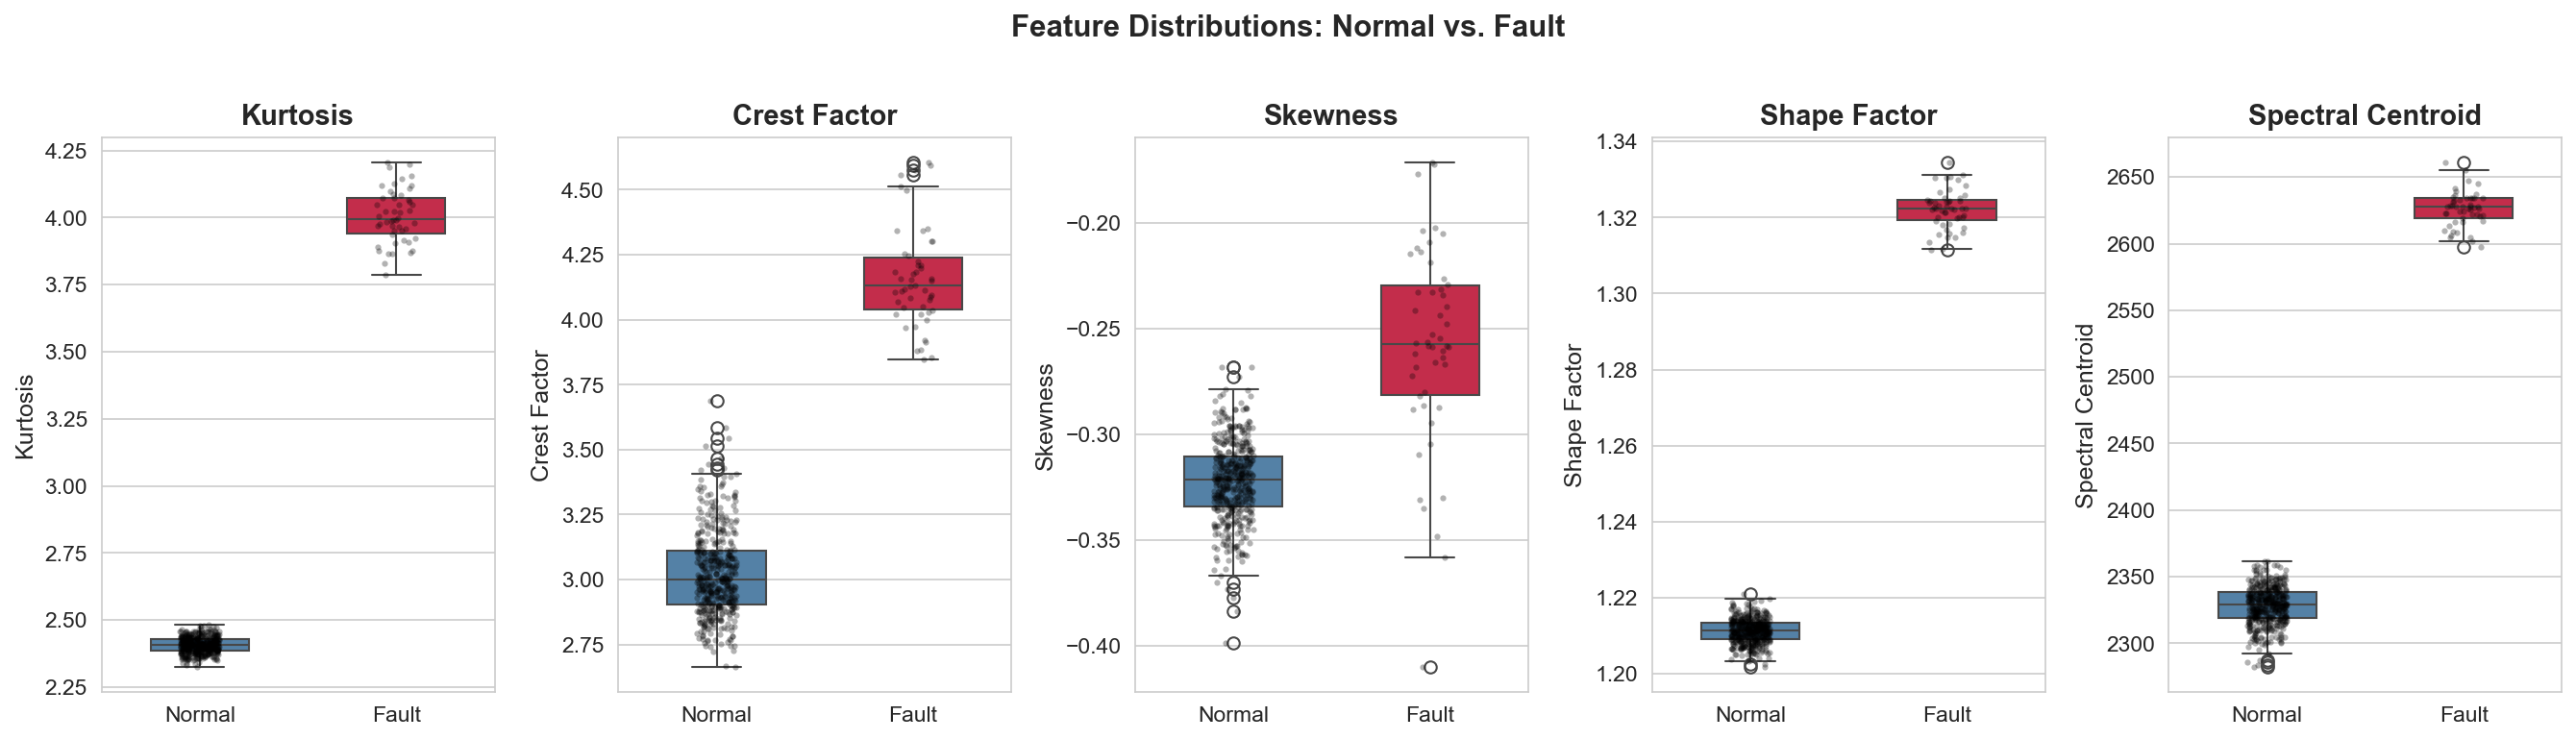

In [21]:
# ============================================================
# §3a — Feature Distributions: Box plots + Strip plots
# ============================================================
fig, axes = plt.subplots(1, 5, figsize=(18, 5))
colors = {'Normal': 'steelblue', 'Fault':'crimson'}

for i, feat in enumerate(feature_names):
    sns.boxplot(data=df, x='Label_str', y=feat, ax=axes[i], palette=colors, width=0.5)
    sns.stripplot(data=df, x='Label_str', y=feat, ax=axes[i], color='black', alpha=0.3, size=3, jitter=True)
    axes[i].set_title(feat, fontweight='bold')
    axes[i].set_xlabel('')

plt.suptitle('Feature Distributions: Normal vs. Fault', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


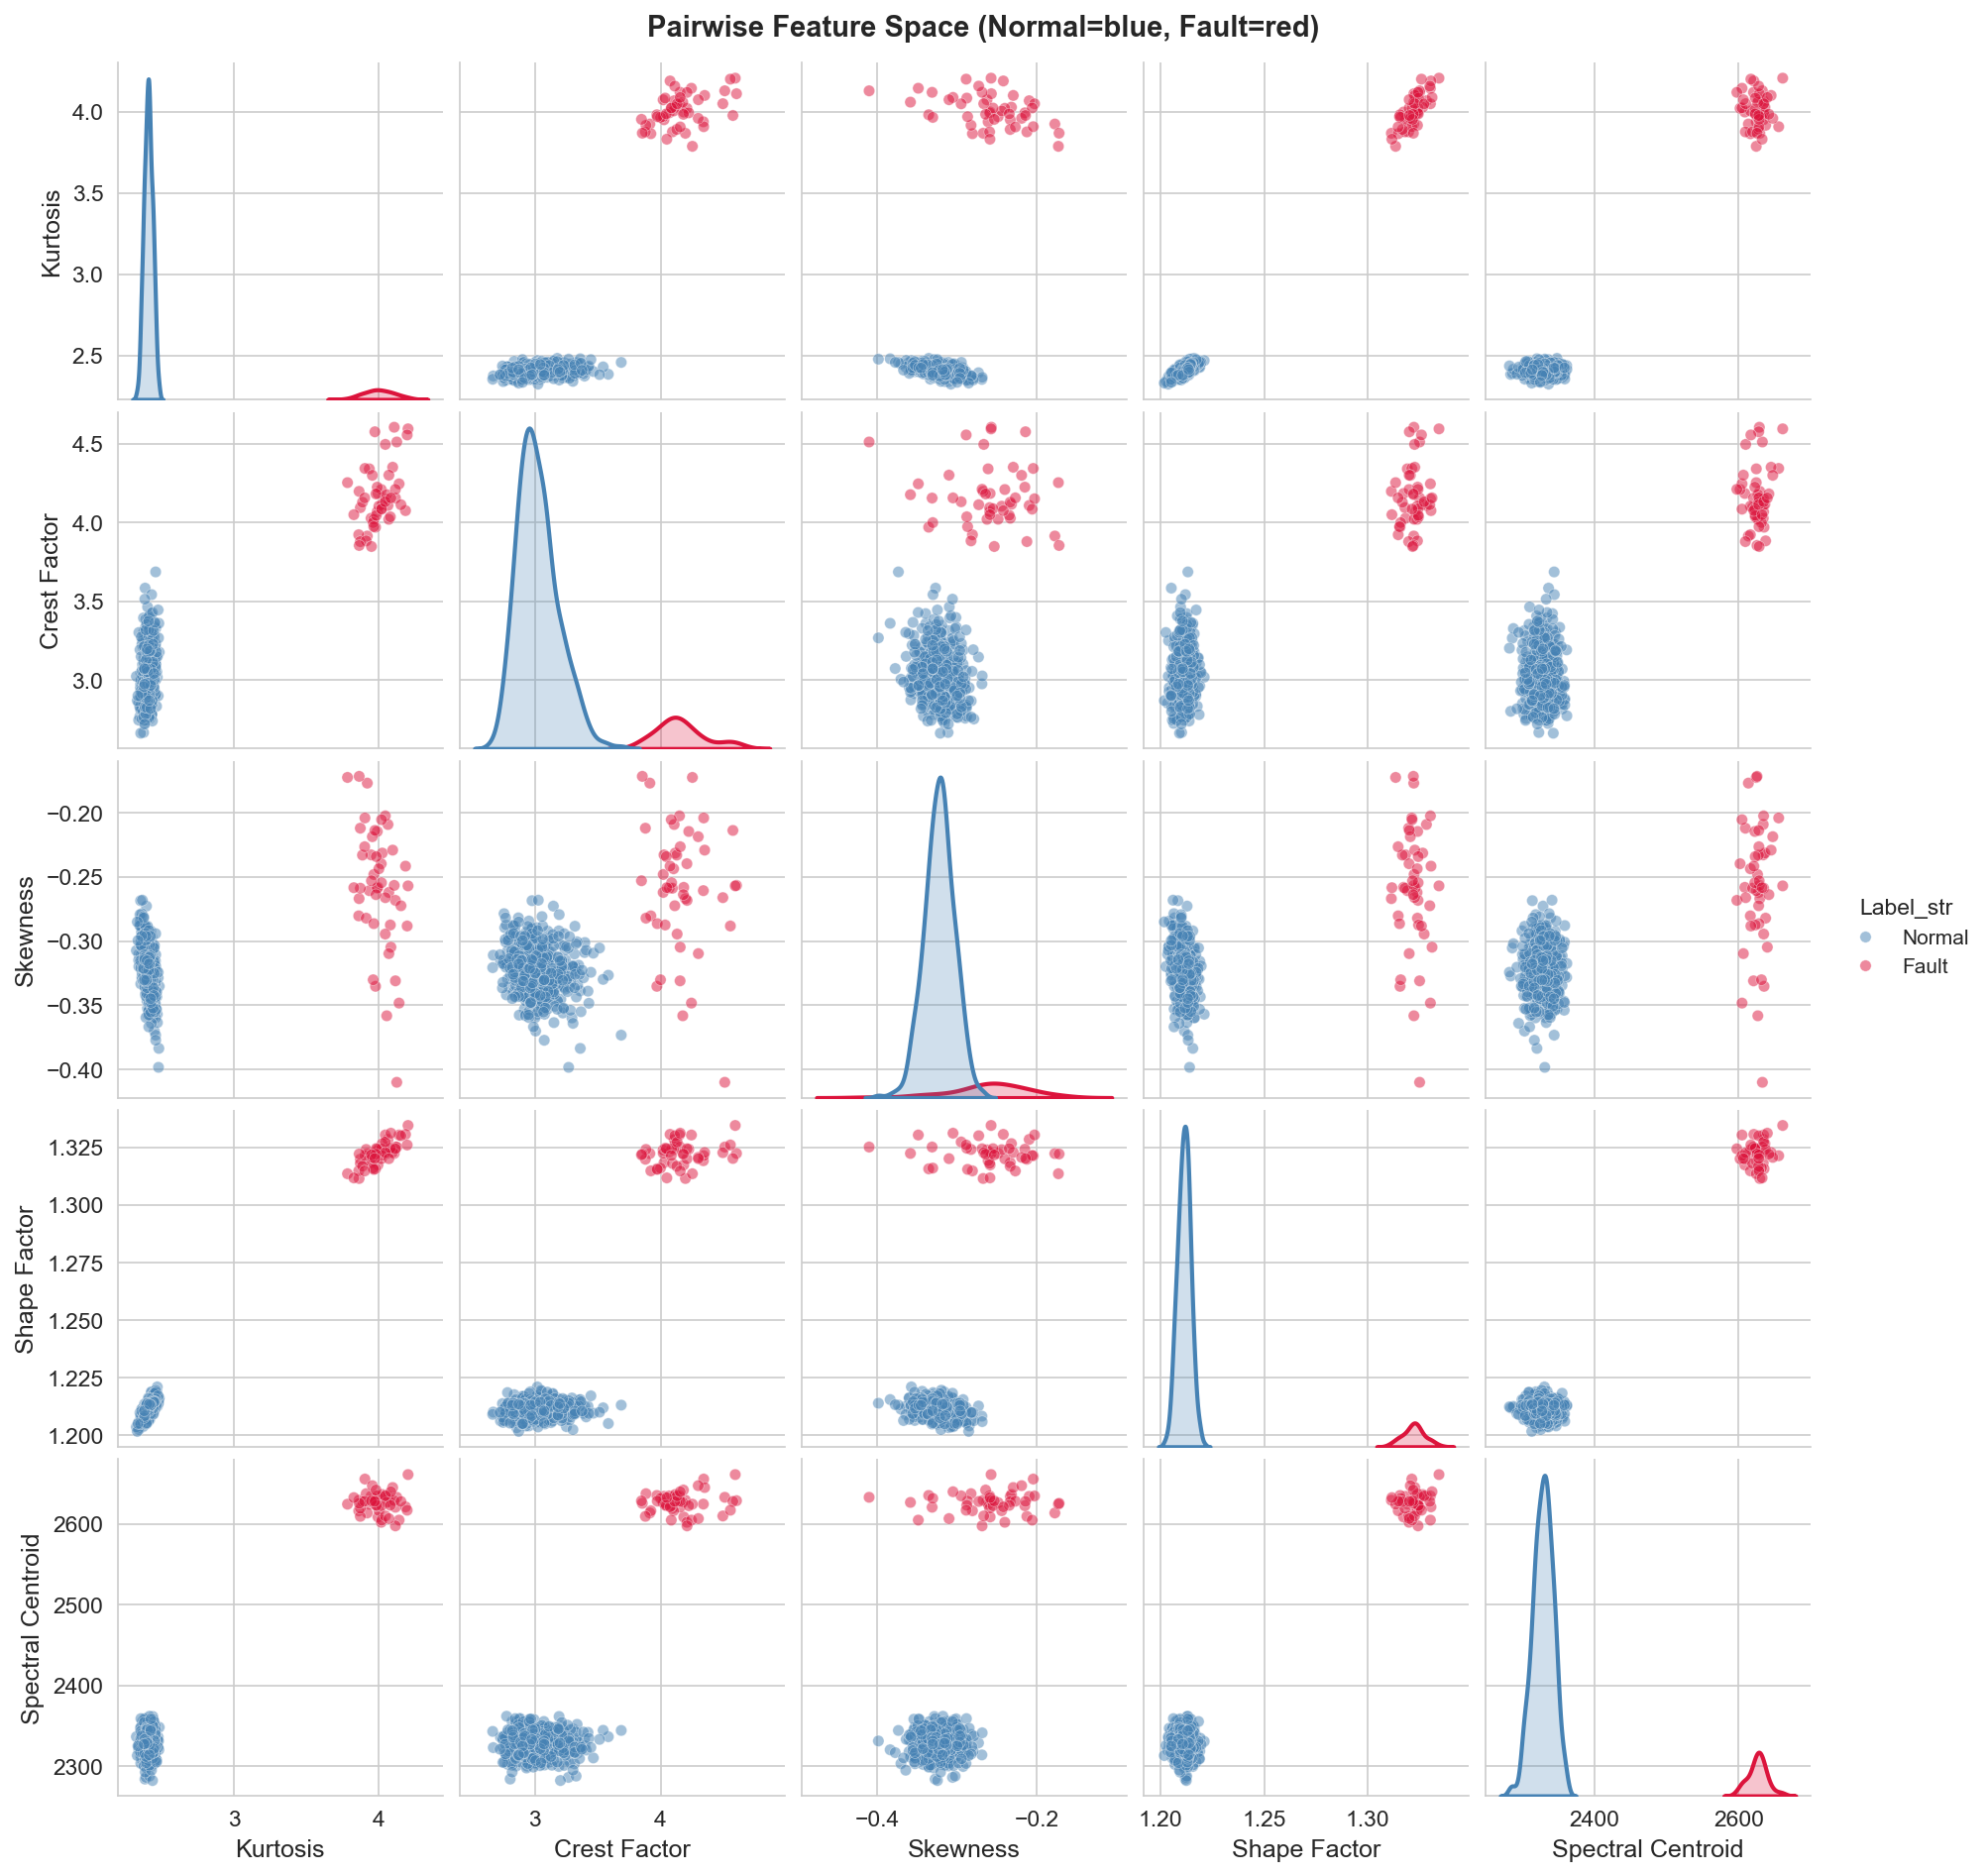

In [33]:
# ============================================================
# §3b — Pairwise Feature Scatter Matrix
# ============================================================
g = sns.pairplot(df, vars=feature_names, hue='Label_str',
                 palette=colors, diag_kind='kde',
                 plot_kws={'alpha':0.5, 's':30, 'edgecolor':'white', 'linewidth':0.3},
                 diag_kws={'linewidth': 2})
g.figure.suptitle('Pairwise Feature Space (Normal=blue, Fault=red)', y=1.01, fontsize=14, fontweight='bold')
plt.show()



Shape of X_scaled (500, 5)
Shape of X_pca (500, 2)


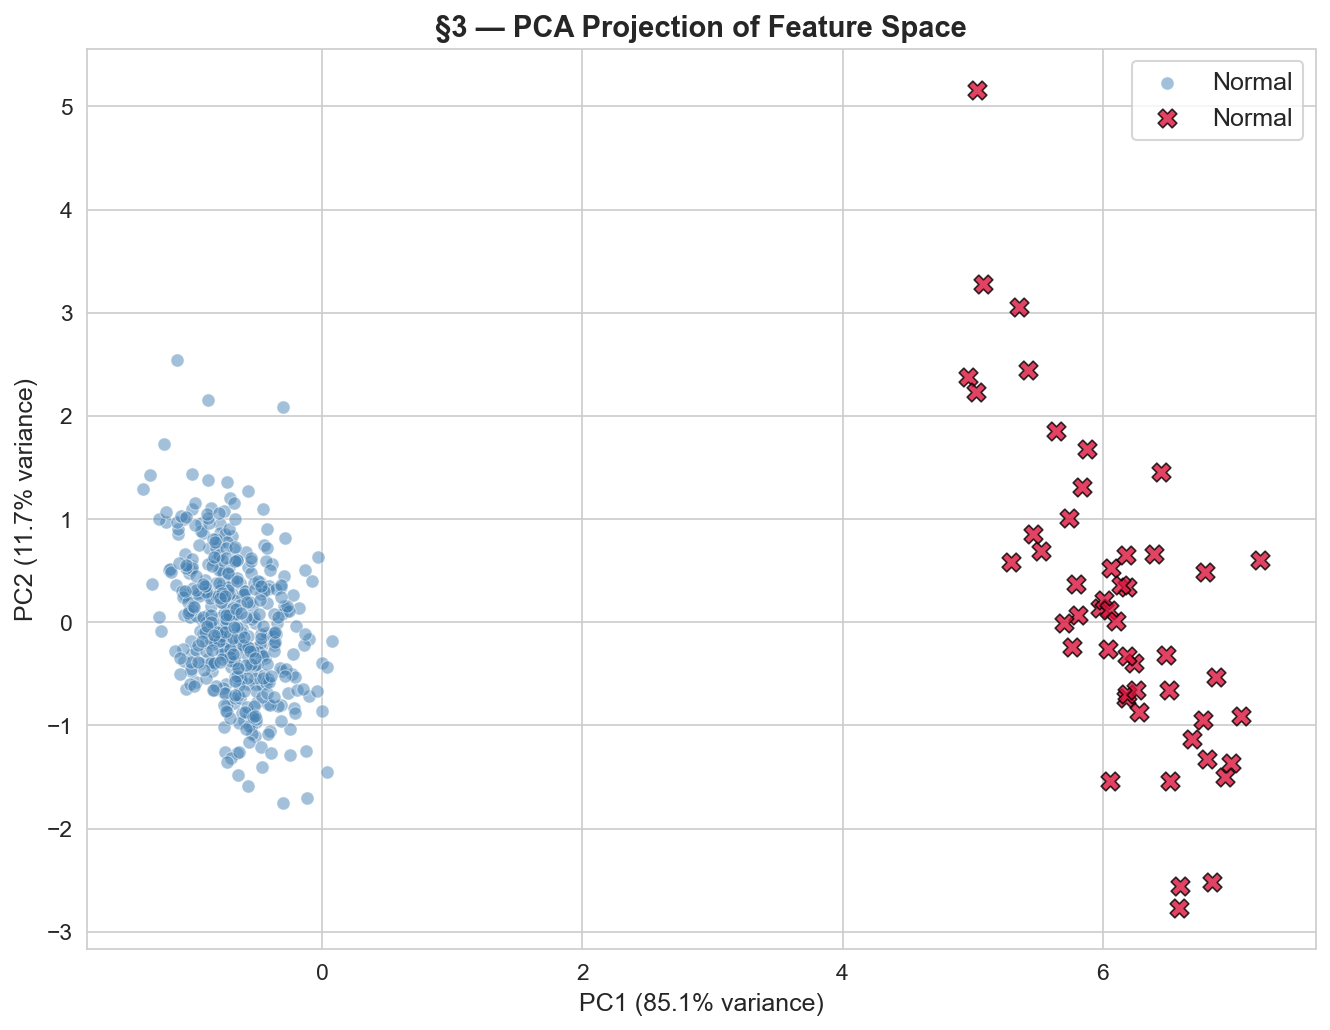

PCA explained variance: PC1=85.1%, PC2=11.7%
Total: 96.8%

🔍 Faulty samples (red X's) should lie away from the normal cluster.


In [ ]:
# ============================================================
# §3c — PCA Projection to 2D (for later decision-boundary plots)
# ============================================================
X = df[feature_names].values
y_true = df['Label'].values # 0 = normal, 1 = fault

# Standardize features (crucial for SVM and LOF)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Shape of X_scaled', X_scaled.shape)

# PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print('Shape of X_pca', X_pca.shape)

fig, ax = plt.subplots(figsize=(9, 7))
scatter_normal = ax.scatter(X_pca[y_true == 0, 0], X_pca[y_true == 0, 1],
                            c='steelblue', s=40, alpha=0.5, edgecolors='white', linewidth=0.5, label='Normal')
scatter_fault = ax.scatter(X_pca[y_true == 1, 0], X_pca[y_true == 1, 1],
                            c='crimson', s=80, alpha=0.8, edgecolors='black', linewidth=0.8, marker='X', label='Fault')

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.set_title('§3 — PCA Projection of Feature Space', fontweight='bold')
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

print(f"PCA explained variance: PC1={pca.explained_variance_ratio_[0]*100:.1f}%, PC2={pca.explained_variance_ratio_[1]*100:.1f}%")
print(f"Total: {sum(pca.explained_variance_ratio_)*100:.1f}%")
print("\n🔍 Faulty samples (red X's) should lie away from the normal cluster.")


## §4 — One-Class SVM

**One-Class SVM** (Schölkopf et al., 2001) learns a **hypersphere** (or more generally, a high-dimensional boundary) around the training data using only normal samples — no fault labels needed.

The key hyperparameter is **`ν` (nu)**:
- Sets an **upper bound** on the fraction of training points allowed outside the boundary (outliers)
- Sets a **lower bound** on the fraction of training points that become support vectors
- Rule of thumb: set `ν ≈` expected contamination rate in your data (here ≈ 0.10)

In [55]:
# ============================================================
# §4a — Train One-Class SVM
# ============================================================

# For anomaly detection, we use contamination ≈ known fault ratio
nu_param = 0.10  # ≈ expected fraction of anomalies

ocsvm = OneClassSVM(kernel='rbf', gamma='scale', nu=nu_param)
ocsvm.fit(X_scaled)

# Predict: +1 = normal (inlier), -1 = anomaly (outlier)
y_pred_ocsvm = ocsvm.predict(X_scaled)

# Convert to our convention: 0 = normal, 1= fault
y_pred_ocsvm_binary = (y_pred_ocsvm == -1).astype(int)

# Decision function scores (more negative = more anomalous)
scores_ocsvm = ocsvm.decision_function(X_scaled)

print("=== One-Class SVM Results ===")
print(f"ν (nu) = {nu_param}")
print(f"Kernel = RBF, γ = 'scale' → {ocsvm._gamma:.4f}")
print(f"Support vectors: {ocsvm.support_vectors_.shape[0]} / {X_scaled.shape[0]} samples")
print(f"\nPredicted Normal: {np.sum(y_pred_ocsvm_binary == 0)}")
print(f"Predicted Fault:  {np.sum(y_pred_ocsvm_binary == 1)}")
print(f"\n{classification_report(y_true, y_pred_ocsvm_binary, target_names=['Normal', 'Fault'])}")

=== One-Class SVM Results ===
ν (nu) = 0.1
Kernel = RBF, γ = 'scale' → 0.2000
Support vectors: 54 / 500 samples

Predicted Normal: 449
Predicted Fault:  51

              precision    recall  f1-score   support

      Normal       0.95      0.95      0.95       450
       Fault       0.53      0.54      0.53        50

    accuracy                           0.91       500
   macro avg       0.74      0.74      0.74       500
weighted avg       0.91      0.91      0.91       500



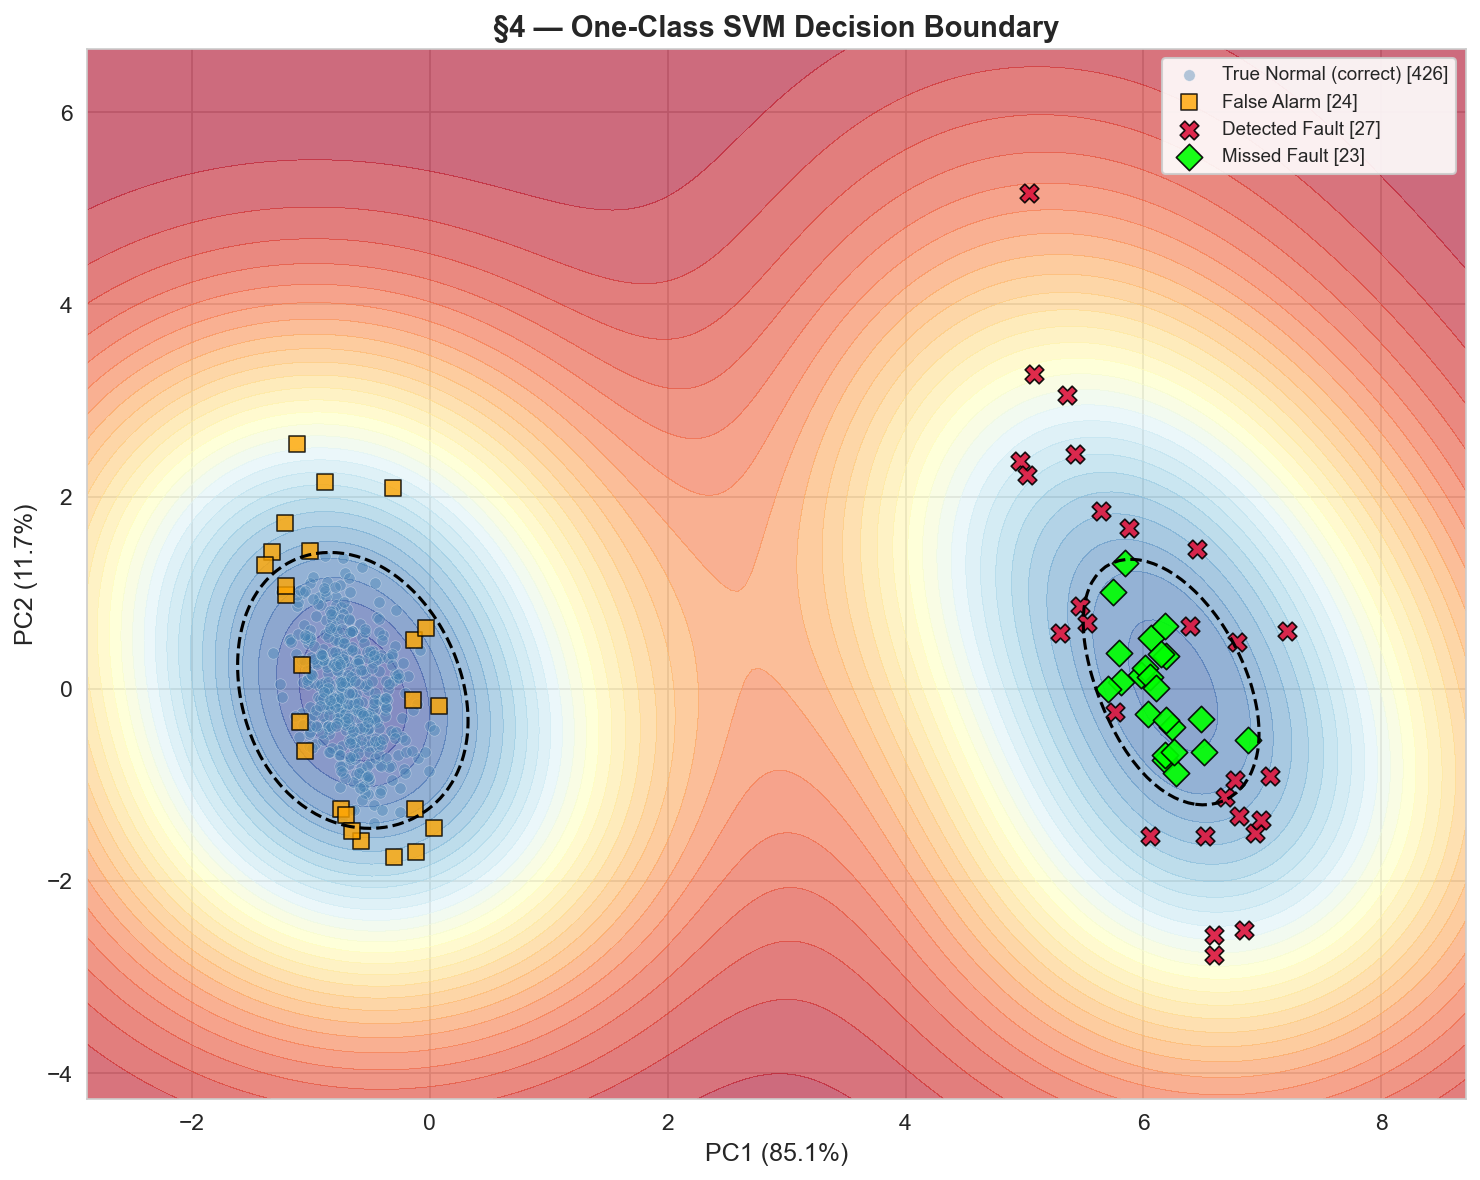

🔍 The BLACK DASHED LINE is the learned decision boundary.
   Points INSIDE (blue region) are classified as normal.
   Points OUTSIDE (red region) are classified as anomalous.


In [ ]:
# ============================================================
# §4b — Visualize One-Class SVM Decision Boundary in PCA Space
# ============================================================

def plot_decision_boundary_pca(model, X_pca, y_true, y_pred, scores, title, ax=None):
    """Plot decision boundary of an anomaly detector in 2D PCA space."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))

    # Create mesh grid
    margin = 1.5
    x_min, x_max = X_pca[:, 0].min() - margin, X_pca[:, 0].max() + margin
    y_min, y_max = X_pca[:, 1].min() - margin, X_pca[:, 1].max() + margin
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))
    
    # Project mesh back to original feature space for prediction
    mesh_pca = np.c_[xx.ravel(), yy.ravel()]
    mesh_original = pca.inverse_transform(mesh_pca)

    # Get decision scores on mesh
    if hasattr(model, 'decision_function'):
        Z = model.decision_function(mesh_original)
    else:
        Z = model.score_samples(mesh_original)
    Z = Z.reshape(xx.shape)

    # Plot distinct regions
    ax.contourf(xx, yy, Z, levels=np.linspace(Z.min(), Z.max(), 30), cmap='RdYlBu', alpha=0.6)
    ax.contour(xx, yy, Z, levels=[0], colors='black', linewidth=2, linestyles='--')

    # True normals predicted normal (true negative)
    mask_tn = (y_true == 0) & (y_pred == 0)
    ax.scatter(X_pca[mask_tn, 0], X_pca[mask_tn, 1], c='steelblue', s=30, alpha=0.4,
               edgecolors='white', linewidth=0.3, label=f'True Normal (correct) [{mask_tn.sum()}]')
    
    # True normals predicted fault (false positive)
    mask_fp = (y_true == 0) & (y_pred == 1)
    ax.scatter(X_pca[mask_fp, 0], X_pca[mask_fp, 1], c='orange', s=60, alpha=0.8,
               edgecolors='black', linewidth=0.8, marker='s', label=f'False Alarm [{mask_fp.sum()}]')
    
    # True faults predicted fault (true positive)
    mask_tp = (y_true == 1) & (y_pred == 1)
    ax.scatter(X_pca[mask_tp, 0], X_pca[mask_tp, 1], c='crimson', s=80, alpha=0.9,
               edgecolors='black', linewidth=0.8, marker='X', label=f'Detected Fault [{mask_tp.sum()}]')
    
    # True faults predicted normal (false negative — MISSED!)
    mask_fn = (y_true == 1) & (y_pred == 0)
    ax.scatter(X_pca[mask_fn, 0], X_pca[mask_fn, 1], c='lime', s=80, alpha=0.9,
               edgecolors='black', linewidth=0.8, marker='D', label=f'Missed Fault [{mask_fn.sum()}]')
    
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.set_title(title, fontweight='bold', fontsize=14)
    ax.legend(loc='best', fontsize=9, framealpha=0.9)
    return ax

fig, ax = plt.subplots(figsize=(10, 8))
plot_decision_boundary_pca(ocsvm, X_pca, y_true, y_pred_ocsvm_binary, scores_ocsvm,
                           '§4 — One-Class SVM Decision Boundary', ax)
plt.tight_layout()
plt.show()

print("🔍 The BLACK DASHED LINE is the learned decision boundary.")
print("   Points INSIDE (blue region) are classified as normal.")
print("   Points OUTSIDE (red region) are classified as anomalous.")


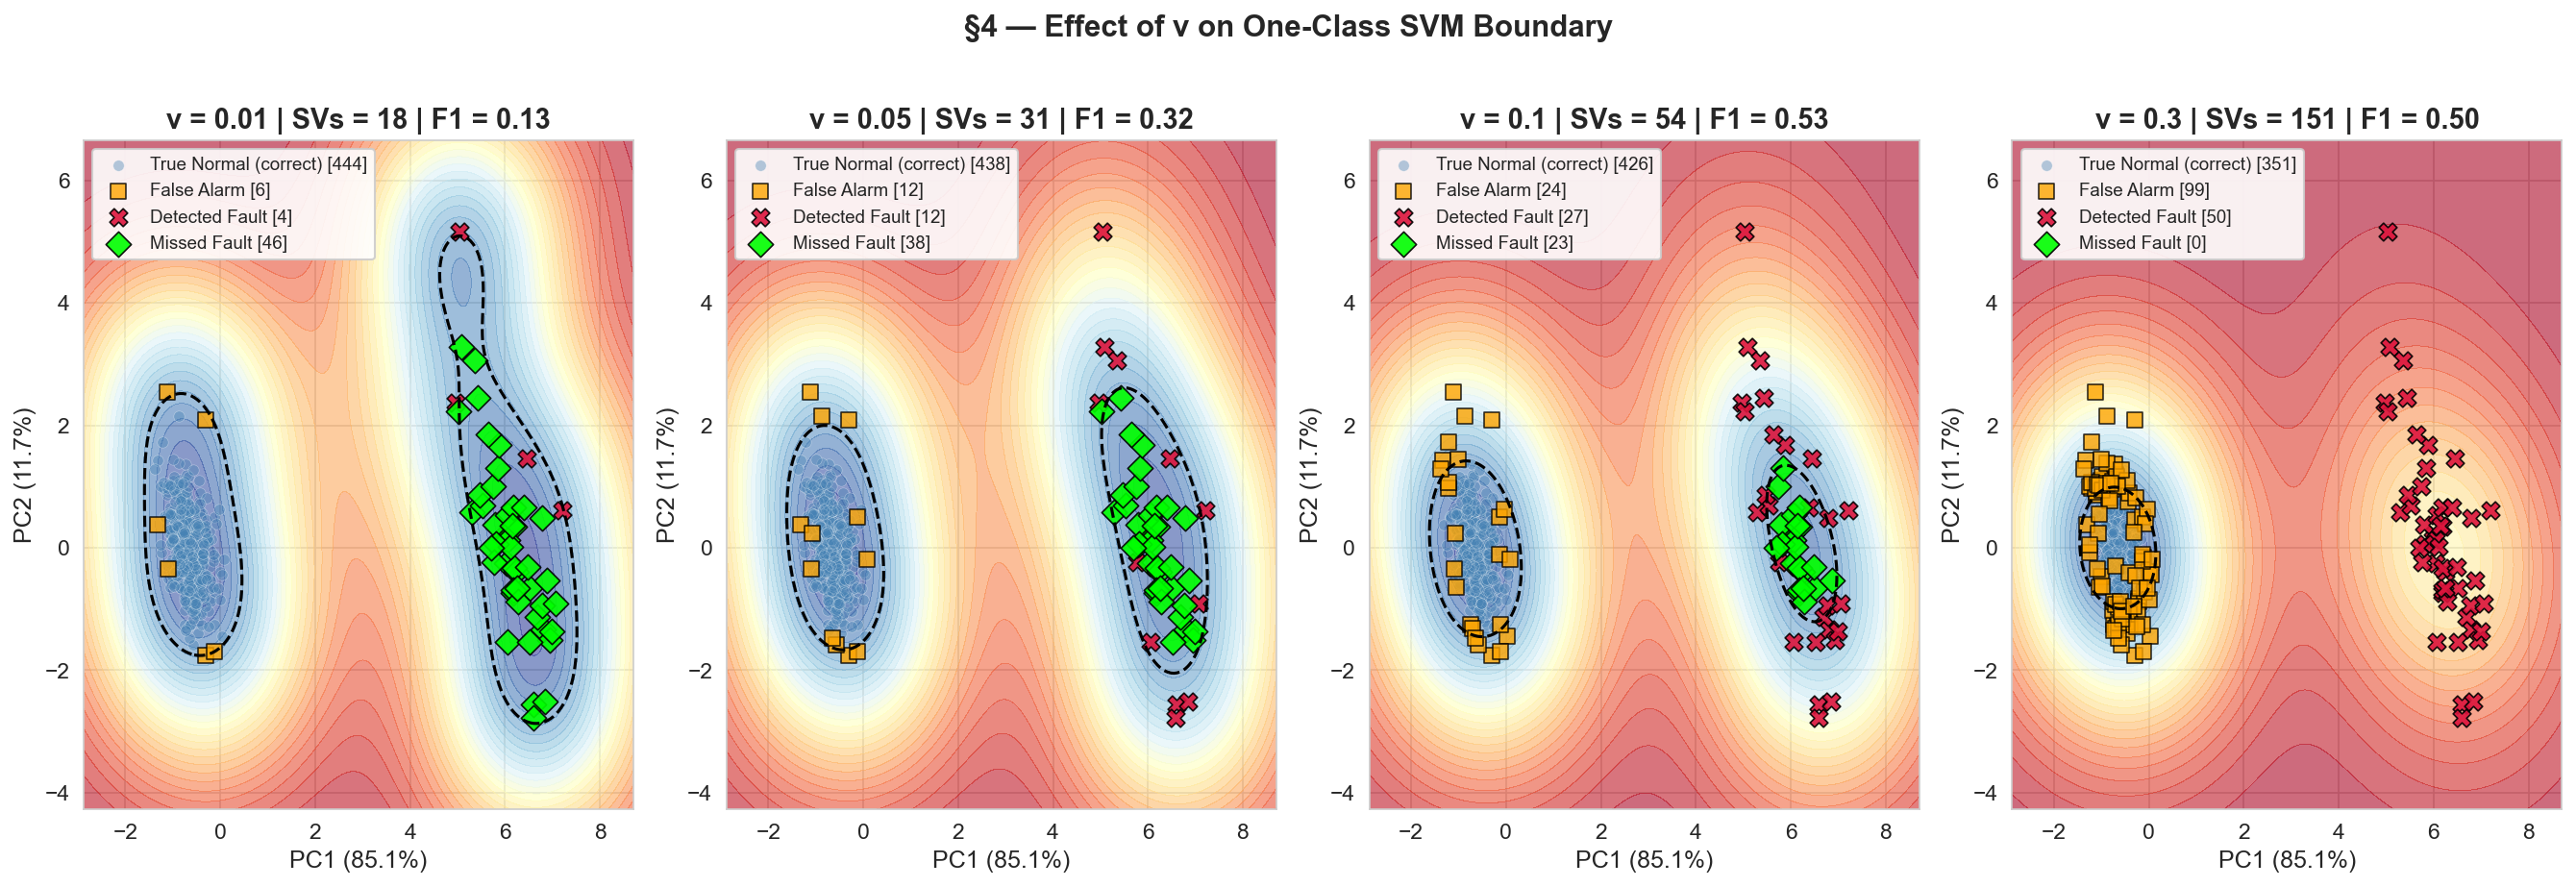

🔍 EXPERIMENT WITH ν:
   ν=0.01 → Very tight boundary, almost no outliers allowed
   ν=0.10 → Balanced — roughly matches our 10% fault rate
   ν=0.30 → Very loose — too many false alarms


In [58]:
# ============================================================
# §4c — Understanding ν: How it changes the boundary
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 6))

for i, nu in enumerate([0.01, 0.05, 0.10, 0.30]):
    model = OneClassSVM(kernel='rbf', gamma='scale', nu=nu)
    model.fit(X_scaled)
    y_pred = (model.predict(X_scaled) == -1).astype(int)
    scores = model.decision_function(X_scaled)

    n_sv = model.support_vectors_.shape[0]
    f1 = f1_score(y_true, y_pred)

    plot_decision_boundary_pca(model, X_pca, y_true, y_pred, scores,
                               f'ν = {nu} | SVs = {n_sv} | F1 = {f1:.2f}', axes[i])
    
plt.suptitle('§4 — Effect of ν on One-Class SVM Boundary', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("🔍 EXPERIMENT WITH ν:")
print("   ν=0.01 → Very tight boundary, almost no outliers allowed")
print("   ν=0.10 → Balanced — roughly matches our 10% fault rate")
print("   ν=0.30 → Very loose — too many false alarms")   

# §5 - Isolation Forest (Deep Dive)

### How it works (intuition)
Isolation Forest (Liu, Ting & Zhou, 2008) takes a fundamentally different approach: instead of modeling "normal", it directly **isolates anomalies**.

**Key idea:** Build an ensemble of random trees (iTrees). At each node, randomly pick a feature and a random split value. Anomalies, being "few and different", get **isolated in fewer splits** → they have **shorter path lengths** from root to leaf.

In [ ]:
# ============================================================
# §5a — Train Isolation Forest
# ============================================================

iforest = IsolationForest(
    n_estimators=200,
    contamination=0.10,
    max_samples='auto',
    random_state=SEED
)
iforest.fit(X_scaled)

# Predict
y_pred_iforest = iforest.predict(X_scaled)
y_pred_iforest_binary = (y_pred_iforest == -1).astype(int)
scores_iforest = iforest.decision_function(X_scaled)

# Count how many samples were classified as normal vs fault
print(f"\nPredicted Normal: {np.sum(y_pred_iforest_binary == 0)}")
print(f"Predicted Fault:  {np.sum(y_pred_iforest_binary == 1)}")

# Print detailed classification report comparing true labels (y_true) to predictions
# Includes precision, recall, F1-score, and support for each class (Normal and Fault)
print(f"\n{classification_report(y_true, y_pred_iforest_binary, target_names=['Normal', 'Fault'])}")



Predcited Normal: 450
Predcited Fault: 50

              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       450
       Fault       0.92      0.92      0.92        50

    accuracy                           0.98       500
   macro avg       0.96      0.96      0.96       500
weighted avg       0.98      0.98      0.98       500



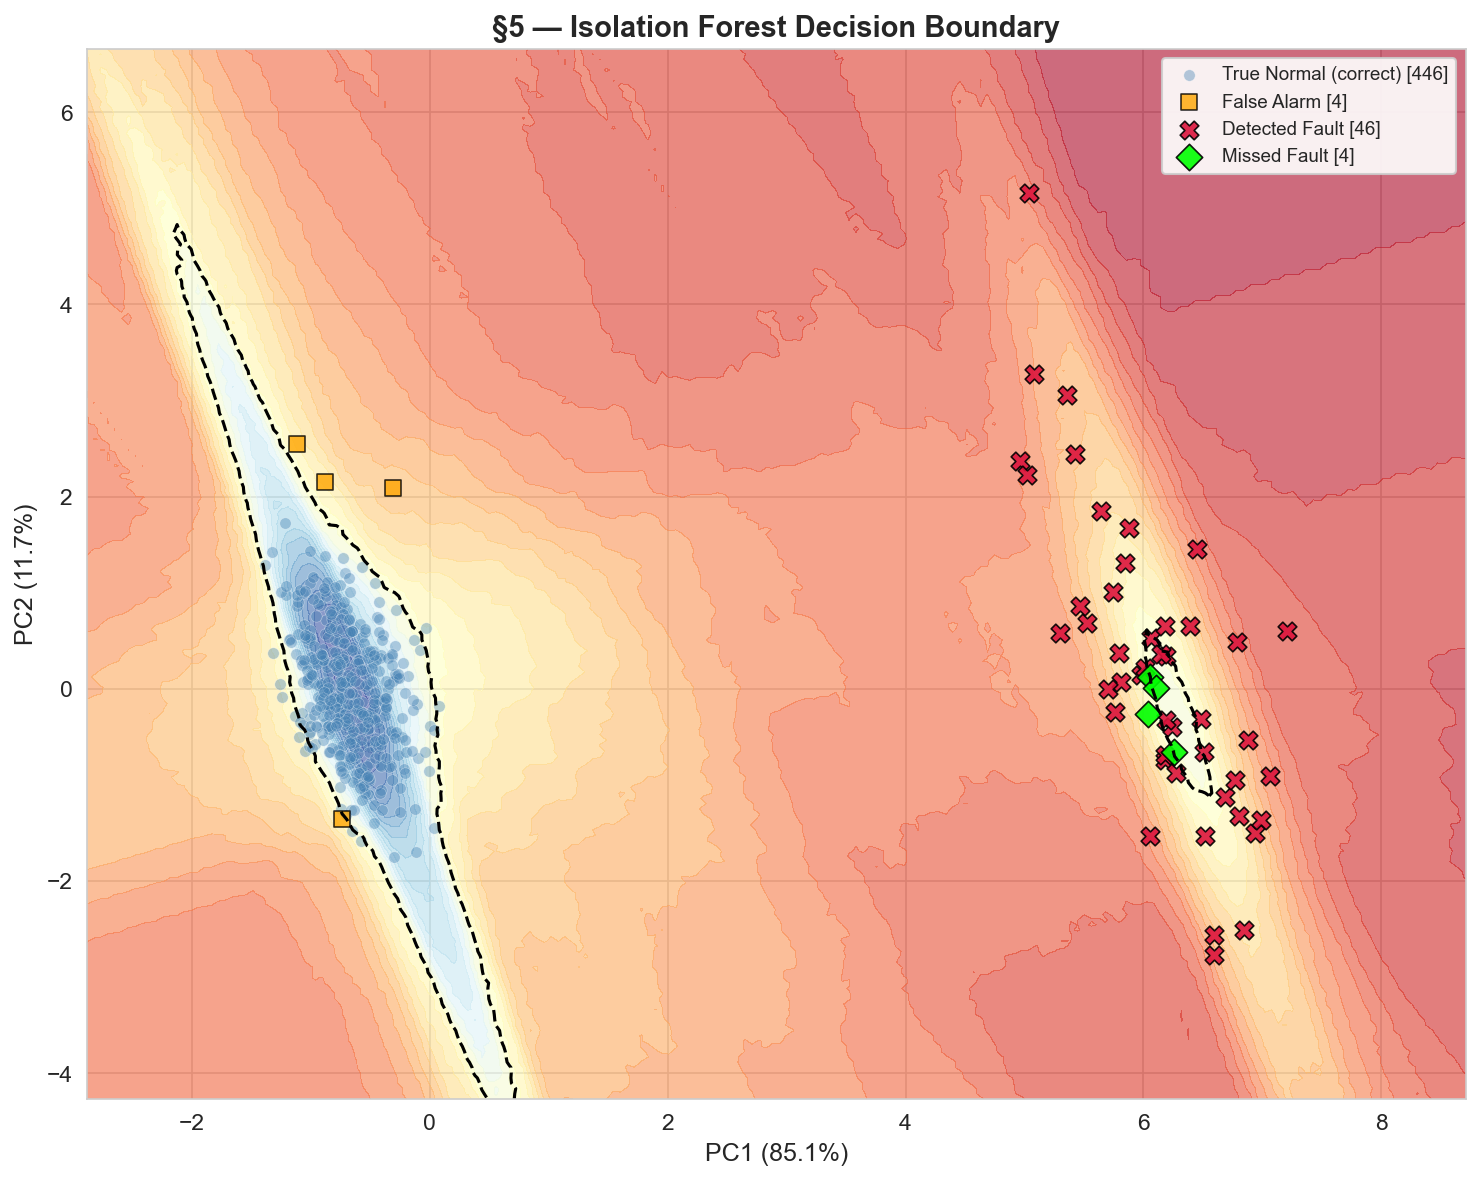

🔍 Compare with One-Class SVM: Isolation Forest's boundary is more 'blocky'
   because it uses axis-aligned splits (like a decision tree).


In [60]:
# ============================================================
# §5b — Visualize Isolation Forest Decision Boundary
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))
plot_decision_boundary_pca(iforest, X_pca, y_true, y_pred_iforest_binary, scores_iforest,
                           '§5 — Isolation Forest Decision Boundary', ax)
plt.tight_layout()
plt.show()

print("🔍 Compare with One-Class SVM: Isolation Forest's boundary is more 'blocky'")
print("   because it uses axis-aligned splits (like a decision tree).")

🔍 The histogram shows clear separation: faulty signals get HIGHER anomaly scores.
   The threshold (dashed line) sets the decision boundary between normal and fault.


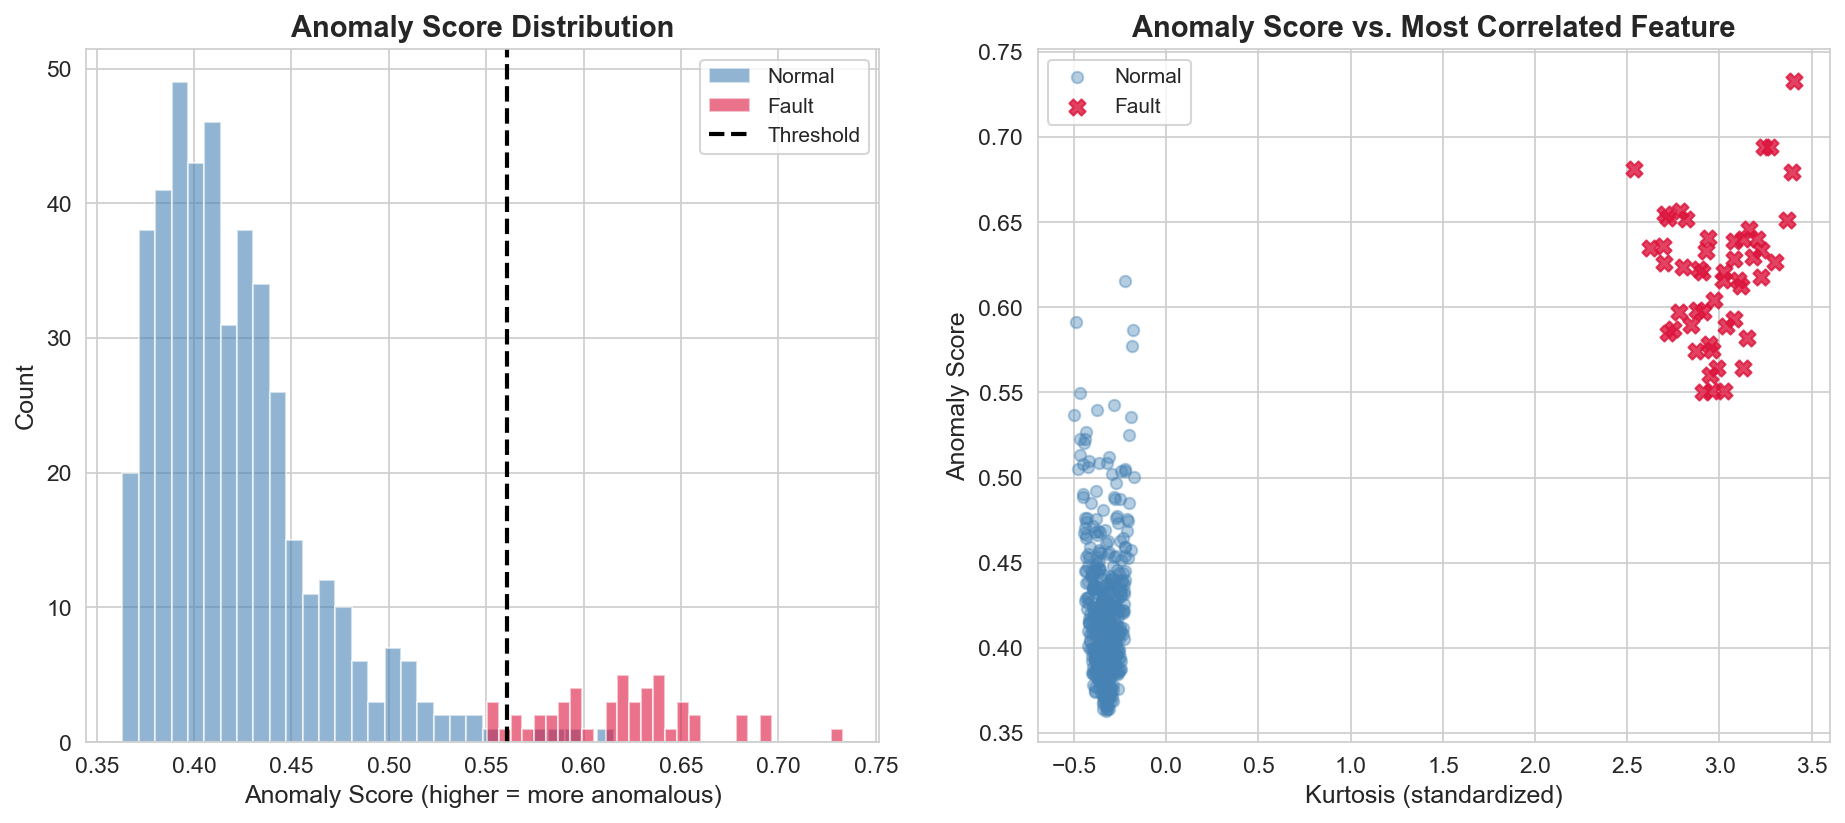

In [ ]:
# ============================================================
# §5c — Visualize Isolation: How path length separates anomalies
# ============================================================

# The anomaly score from sklearn is based on the average path length.
# score_samples returns the raw anomaly score (opposite sign of decision_function)
raw_scores = -iforest.score_samples(X_scaled)  # Higher = more anomalous

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Score distribution
for label, color, name in [(0, 'steelblue', 'Normal'), (1, 'crimson', 'Fault')]:
    axes[0].hist(raw_scores[y_true == label], bins=30, alpha=0.6, color=color, label=name, edgecolor='white')
axes[0].axvline(x=np.percentile(raw_scores, 100*(1-0.10)), color='black', linestyle='--', linewidth=2, label='Threshold')
axes[0].set_xlabel('Anomaly Score (higher = more anomalous)')
axes[0].set_ylabel('Count')
axes[0].set_title('Anomaly Score Distribution', fontweight='bold')
axes[0].legend()

# Score vs. the most correlated feature
feat_importance_idx = np.argsort([np.abs(np.corrcoef(raw_scores, X_scaled[:, i])[0, 1]) for i in range(5)])[::-1]
top_feat = feat_importance_idx[0]
axes[1].scatter(X_scaled[y_true == 0, top_feat], raw_scores[y_true == 0],
                c='steelblue', alpha=0.4, s=30, label='Normal')
axes[1].scatter(X_scaled[y_true == 1, top_feat], raw_scores[y_true == 1],
                c='crimson', alpha=0.8, s=60, marker='X', label='Fault')
axes[1].set_xlabel(f'{feature_names[top_feat]} (standardized)')
axes[1].set_ylabel('Anomaly Score')
axes[1].set_title('Anomaly Score vs. Most Correlated Feature', fontweight='bold')
axes[1].legend()

plt.suptitle('§5 — Isolation Forest: Anomaly Score Analysis', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("🔍 The histogram shows clear separation: faulty signals get HIGHER anomaly scores.")
print("   The threshold (dashed line) sets the decision boundary between normal and fault.")


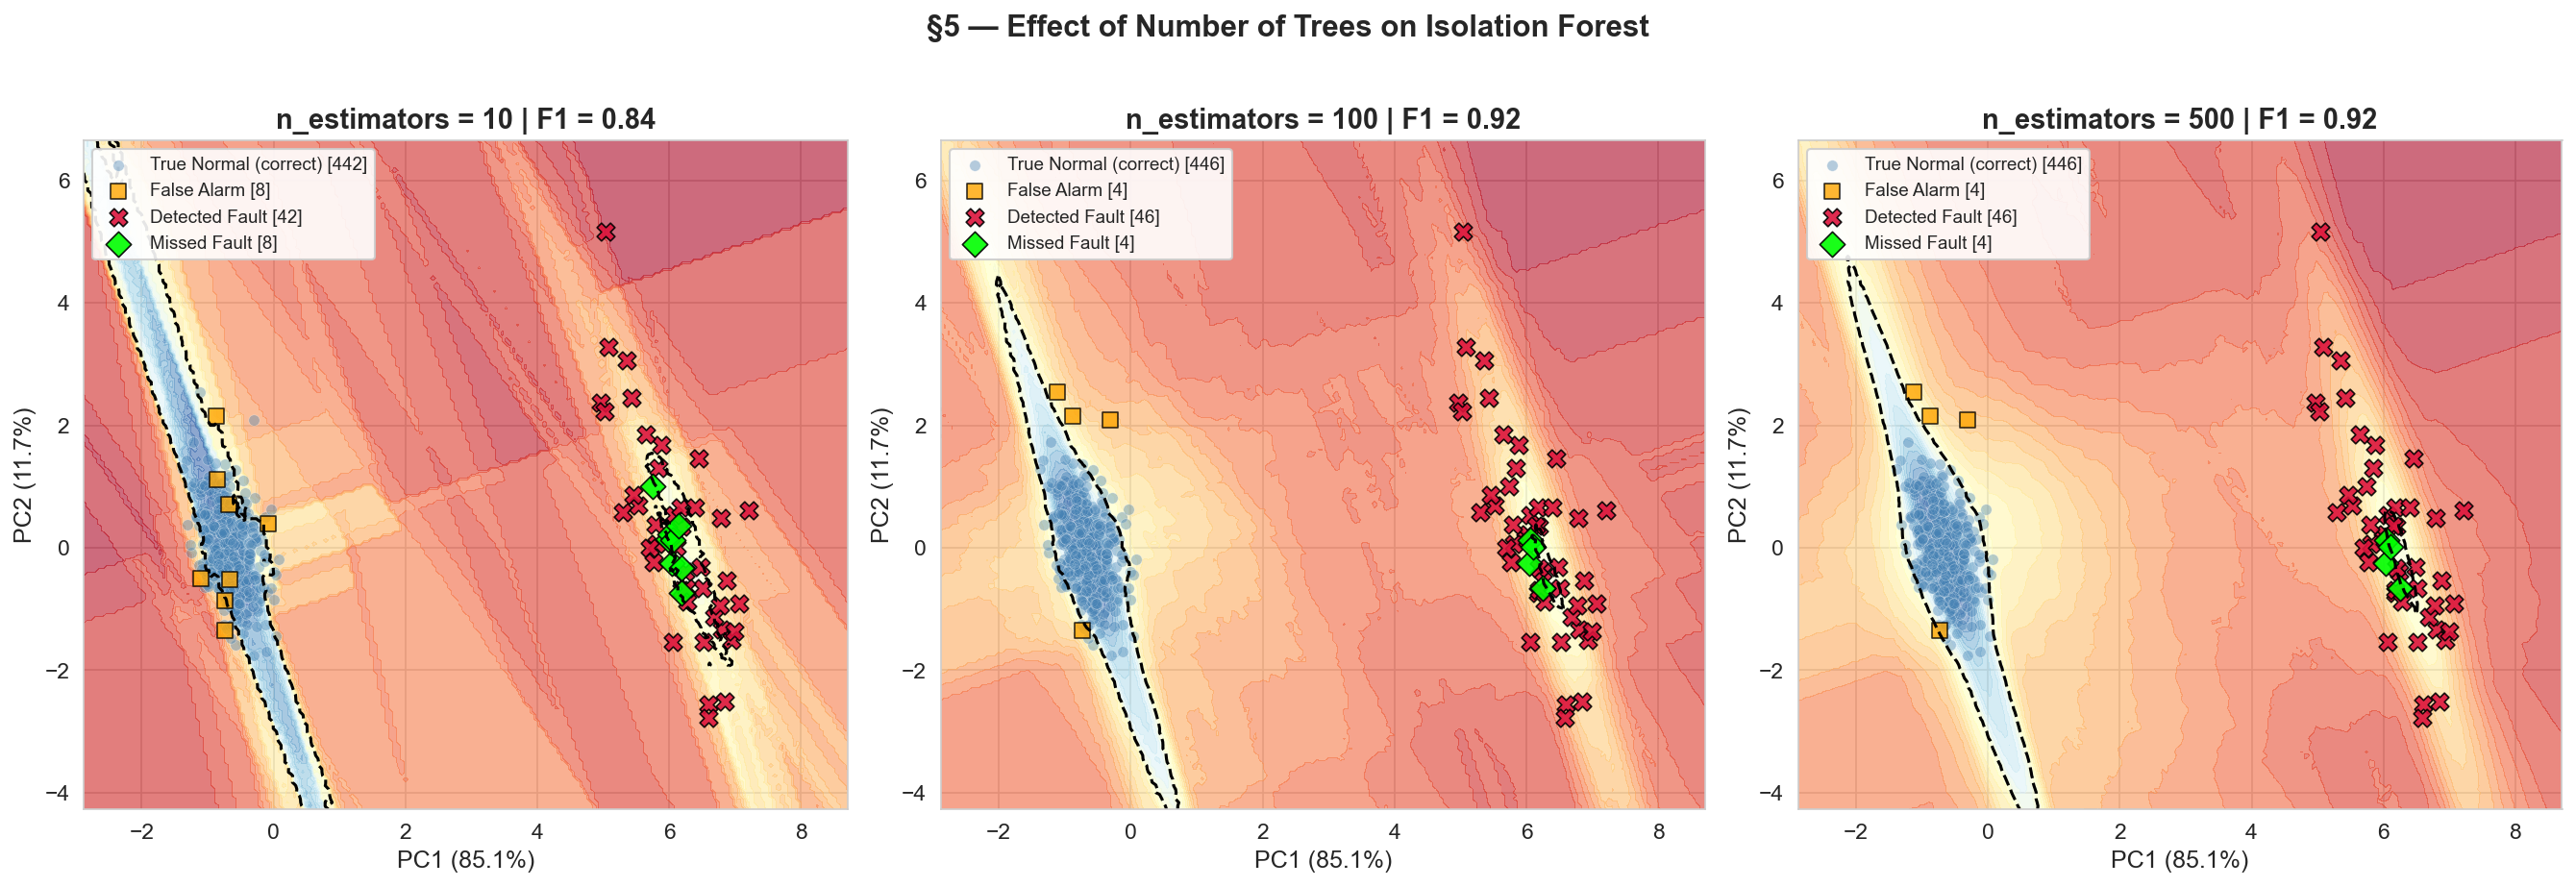

🔍 More trees → smoother, more stable decision boundary
   Too few trees → noisy, unstable boundaries


In [ ]:
# ============================================================
# §5d — Effect of n_estimators on Isolation Forest
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, n_est in enumerate([10, 100, 500]):
    model = IsolationForest(n_estimators=n_est, contamination=0.10, random_state=SEED)
    model.fit(X_scaled)
    y_pred = (model.predict(X_scaled) == -1).astype(int)
    scores = model.decision_function(X_scaled)
    f1 = f1_score(y_true, y_pred)
    
    plot_decision_boundary_pca(model, X_pca, y_true, y_pred, scores,
                               f'n_estimators = {n_est} | F1 = {f1:.2f}', axes[i])

plt.suptitle('§5 — Effect of Number of Trees on Isolation Forest', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("🔍 More trees → smoother, more stable decision boundary")
print("   Too few trees → noisy, unstable boundaries")